# Spotify Mood DJ — Build It Yourself

Welcome. In this notebook you will build a project that analyzes 60,000 real Spotify tracks
and ends with a working playlist generator.

You already know Python, NumPy, Pandas, and Seaborn cheatsheets. That is all you need.

**Rules:**
- Do not skip cells.
- Read the markdown, then write the code yourself.
- If you get stuck, look up the function name mentioned in the hint.
- The goal is not perfection. The goal is a working project you can show someone.

**Dataset:** Spotify Tracks Dataset (Kaggle) — `spotify_tracks.csv`
Download it and upload it to Colab before starting.

Link: https://www.kaggle.com/datasets/gauthamvijayaraj/spotify-tracks-dataset-updated-every-week/data

## Step 1 — Imports

We need three libraries:
- `pandas` for data handling
- `numpy` for missing-value handling
- `seaborn` for every plot

We also set a seaborn theme so plots look nice by default.
No matplotlib imports. Seaborn handles everything.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

sns.set_theme()

## Step 2 — Load the dataset

Read `spotify_tracks.csv` into a DataFrame called `df`.

Then:
1. Print the shape (rows, columns)
2. Print the column names
3. Display the first 5 rows

This is your "look before you touch" step. Never analyze a dataset you haven't looked at.

In [4]:
df = pd.read_csv('spotify_tracks.csv')

print("Dataset Shape:", df.shape)

print("Column Names:", df.columns.tolist())

print("First 5 Rows:")
print(df.head())

Dataset Shape: (62317, 22)
Column Names: ['track_id', 'track_name', 'artist_name', 'year', 'popularity', 'artwork_url', 'album_name', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'time_signature', 'valence', 'track_url', 'language']
First 5 Rows:
                 track_id                                  track_name  \
0  2r0ROhr7pRN4MXDMT1fEmd                  Leo Das Entry (From "Leo")   
1  4I38e6Dg52a2o2a8i5Q5PW                                AAO KILLELLE   
2  59NoiRhnom3lTeRFaBzOev      Mayakiriye Sirikiriye - Orchestral EDM   
3  5uUqRQd385pvLxC8JX3tXn    Scene Ah Scene Ah - Experimental EDM Mix   
4  1KaBRg2xgNeCljmyxBH1mo  Gundellonaa X I Am A Disco Dancer - Mashup   

                                         artist_name  year  popularity  \
0                                Anirudh Ravichander  2024          59   
1  Anirudh Ravichander, Pravin Mani, Vaishali Sri...  2024          47 

## Step 3 — Cleaning

The dataset has three problems:

1. **Useless columns.** `track_id`, `artwork_url`, and `track_url` are not useful for analysis. Drop them.

2. **Fake missing values.** Spotify marks unavailable audio features as `-1` instead of `NaN`.
   If you don't fix this, every average you compute will be wrong.
   Replace `-1` with `NaN` in these columns:
   `acousticness, danceability, energy, instrumentalness, liveness, loudness,
   speechiness, tempo, valence, popularity, key, mode, time_signature`

3. **Missing target.** We cannot analyze popularity if popularity is missing. Drop rows where `popularity` is NaN.

Finally, create a new column `duration_min` by dividing `duration_ms` by 60000, because minutes are more readable than milliseconds.

At the end, print the new shape and the count of each language.

In [10]:
df = df.drop(columns=["track_id", "artwork_url", "track_url"], errors="ignore")


audio_cols = ["acousticness","danceability","energy","instrumentalness","liveness", "loudness","speechiness","tempo","valence","popularity","key","mode","time_signature"]
df[audio_cols] = df[audio_cols].replace(-1, np.nan)


df = df.dropna(subset=["popularity"])

df["duration_min"] = df["duration_ms"] / 60000

print(df.shape)
print(df["language"].value_counts())

(62317, 22)
language
English      23392
Unknown      13005
Tamil        12681
Korean        6893
Hindi         5740
Telugu         324
Malayalam      282
Name: count, dtype: int64


## Step 4 — Create `popularity_tier` and `mood`

Two new columns make everything else possible.

### popularity_tier
Use `pd.cut` to bucket popularity into four labels:
- 0–20 → "Underground"
- 20–50 → "Mid"
- 50–75 → "Popular"
- 75–100 → "Hit"

Hint: bins = [-1, 20, 50, 75, 100] and labels = [...]. Add `observed=True` later when grouping.

### mood
The Russell circumplex splits emotion into four quadrants using **valence** (how positive)
and **energy** (how intense). The cutoff for both is 0.5.

- valence ≥ 0.5 and energy ≥ 0.5 → "Happy / Party"
- valence ≥ 0.5 and energy < 0.5 → "Chill / Relaxed"
- valence < 0.5 and energy ≥ 0.5 → "Angry / Intense"
- valence < 0.5 and energy < 0.5 → "Sad / Melancholy"

If valence or energy is NaN, return "Unknown".

Write a function `tag_mood(row)` and apply it across the DataFrame.

At the end, print the count of each mood.

In [8]:
bins = [-1, 20, 50, 75, 100]
labels = ["Underground", "Mid", "Popular", "Hit"]
df["popularity_tier"] = pd.cut(df["popularity"], bins=bins, labels=labels)


def tag_mood(row):
    v = row["valence"]
    e = row["energy"]

    if pd.isna(v) or pd.isna(e):
        return "Unknown"
    elif v >= 0.5 and e >= 0.5:
        return "Happy / Party"
    elif v >= 0.5 and e < 0.5:
        return "Chill / Relaxed"
    elif v < 0.5 and e >= 0.5:
        return "Angry / Intense"
    else:
        return "Sad / Melancholy"


df["mood"] = df.apply(tag_mood, axis=1)


print(df["mood"].value_counts())

mood
Happy / Party       26990
Angry / Intense     15720
Sad / Melancholy    14803
Chill / Relaxed      4769
Unknown                35
Name: count, dtype: int64


## Step 5 — What do popular songs sound like?

Group the DataFrame by `popularity_tier` and compute the **mean** of these features:

`danceability, energy, valence, acousticness, instrumentalness, speechiness, loudness, tempo`

Use `observed=True` in the groupby.

Round the result to 3 decimals and display it.

**What to look for:** Which tier has the highest danceability? The highest energy?
Is there a clear trend, or is it flat? Write one sentence in a comment about what you see.

In [12]:

features = ["danceability","energy", "valence","acousticness","instrumentalness","speechiness","loudness","tempo"]


tier_means = (df.groupby("popularity_tier", observed=True)[features].mean().round(3))


print(tier_means)


                 danceability  energy  valence  acousticness  \
popularity_tier                                                
Underground             0.593   0.581    0.494         0.388   
Mid                     0.601   0.644    0.495         0.320   
Popular                 0.636   0.684    0.527         0.264   
Hit                     0.646   0.667    0.494         0.212   

                 instrumentalness  speechiness  loudness    tempo  
popularity_tier                                                    
Underground                 0.171        0.092   -84.116  117.605  
Mid                         0.112        0.080   -27.606  118.447  
Popular                     0.023        0.085    -6.290  120.461  
Hit                         0.006        0.073    -6.159  119.261  


## Step 6 — Visualize features by popularity tier

We want to see the distribution, not just the mean.

Use `df.melt()` to reshape the data so every feature is in one long column,
then use `sns.catplot` with `kind="box"` and `col="feature"` and `col_wrap=4`.

Set `sharey=False` so each subplot scales independently, `showfliers=False` to hide outliers,
and `height=3`.

Hint: `melt` takes `id_vars`, `value_vars`, `var_name`, `value_name`.

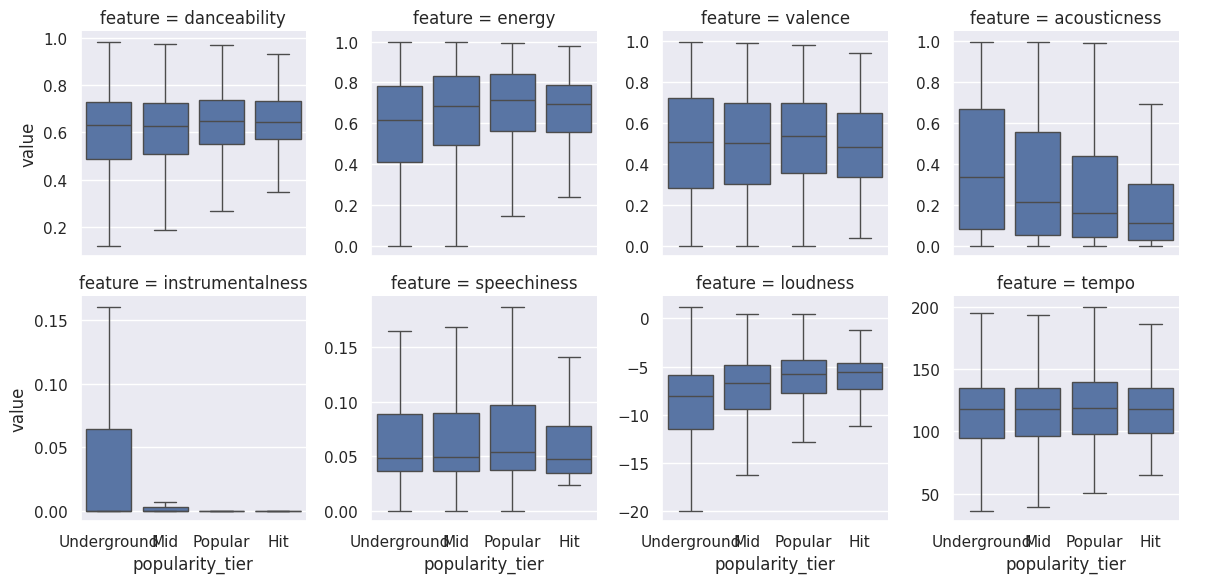

In [17]:
melted_df = df.melt(
    id_vars=["popularity_tier"],
    value_vars=[
        "danceability",
        "energy",
        "valence",
        "acousticness",
        "instrumentalness",
        "speechiness",
        "loudness",
        "tempo",
    ],
    var_name="feature",
    value_name="value",
)


sns.catplot(
    data=melted_df,
    x="popularity_tier",
    y="value",
    col="feature",
    col_wrap=4,
    kind="box",
    sharey=False,
    showfliers=False,
    height=3,
)

## Step 7 — Which features correlate with popularity?

Compute the correlation matrix between every audio feature and `popularity`.

Plot it with `sns.heatmap`, using `annot=True`, `fmt=".2f"`, `cmap="coolwarm"`, and `center=0`.

**What to look for:** The `popularity` row. Are any correlations strong?
If they are all weak, that is a finding — write it down.

<Axes: >

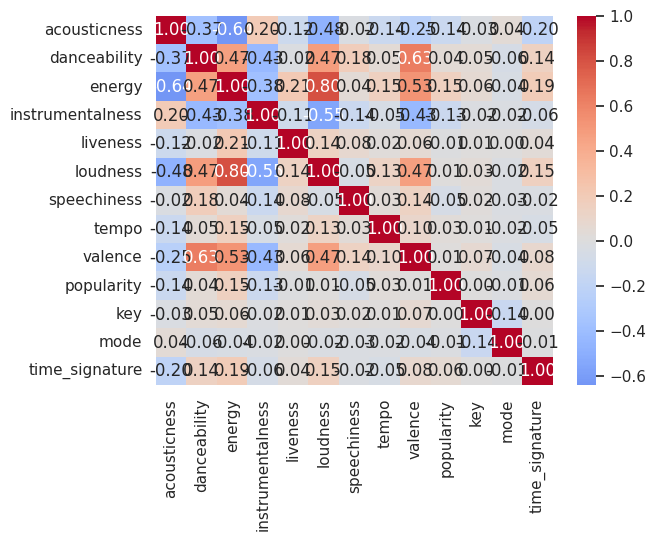

In [16]:
corr_cols = audio_cols
corr_matrix = df[corr_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)


## Step 8 — The mood map

This is the money plot. Valence on x, energy on y, color by mood, size by popularity.

Take a random sample of 3000 rows (drop NaN in energy/valence first) and use `sns.relplot`
with `hue="mood"`, `size="popularity"`, `sizes=(10, 200)`, `alpha=0.6`.

Set `height=7` and `aspect=1.3`.

You should see four visible clusters. The biggest bubbles are the hits.

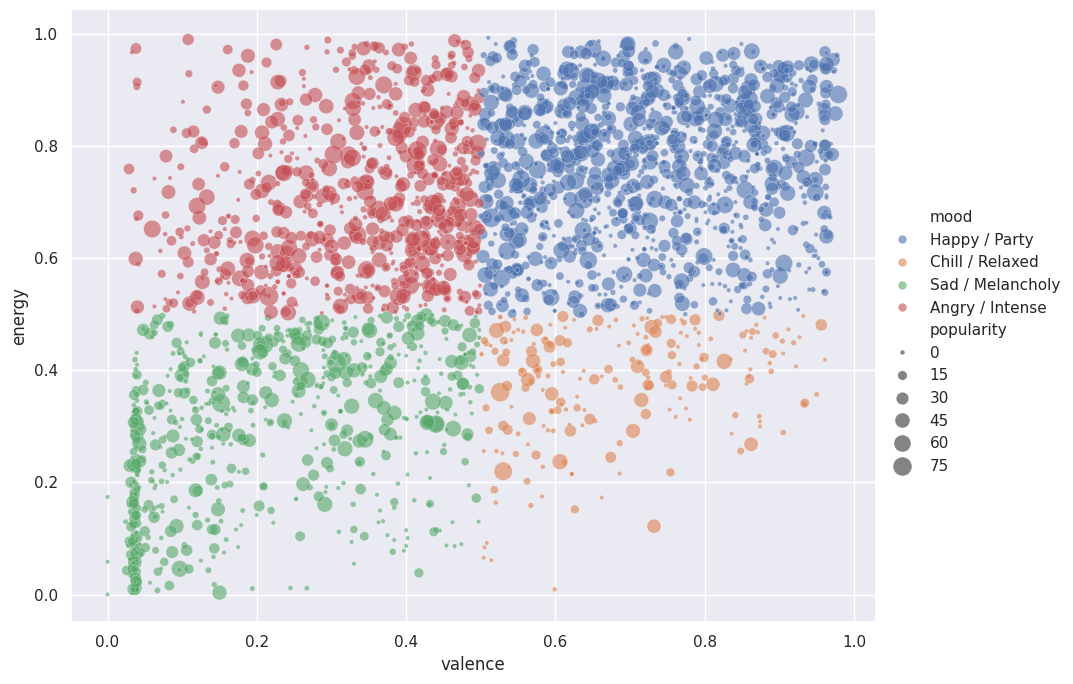

In [18]:
sample_df = df.dropna(subset=["energy", "valence"]).sample(n=3000, random_state=42)

sns.relplot(
    data=sample_df,
    x="valence",
    y="energy",
    hue="mood",
    size="popularity",
    sizes=(10, 200),
    alpha=0.6,
    height=7,
    aspect=1.3,
)

## Step 9 — Mood distribution across languages

Group by both `language` and `mood`, get the size of each group,
and reset the index so it becomes a flat DataFrame with a "count" column.

Then use `sns.catplot` with `kind="bar"`, `x="language"`, `y="count"`, `hue="mood"`,
`height=5`, `aspect=2`.

**What to look for:** Does any language stand out as unusually sad or unusually happy?

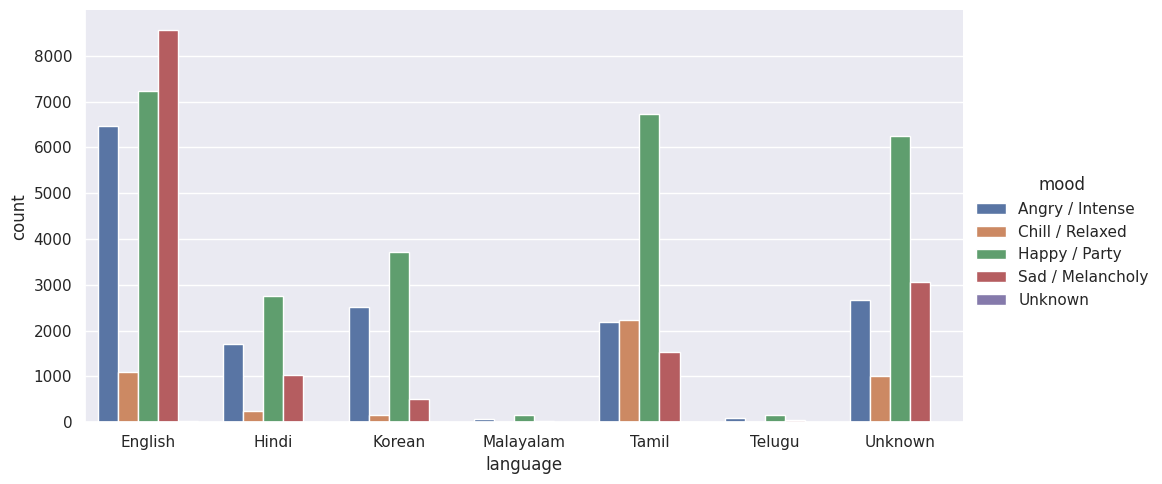

In [19]:
lang_mood_counts = (
    df.groupby(["language", "mood"], observed=True)
    .size()
    .reset_index(name="count")
)


sns.catplot(
    data=lang_mood_counts,
    kind="bar",
    x="language",
    y="count",
    hue="mood",
    height=5,
    aspect=2,
)

## Step 10 — Build `mood_dj()`

This is the actual product. Write a function with this signature:

    mood_dj(mood, language=None, min_popularity=50, n=10)

It should:
1. Validate that `mood` is one of the four valid moods. If not, raise a `ValueError`.
2. Filter `df` to rows where `mood` matches and `popularity >= min_popularity`.
3. If `language` is given, filter further.
4. Sort by popularity descending.
5. Remove duplicate `(track_name, artist_name)` pairs.
6. Take the top `n` rows.
7. Return only these columns:
   `track_name, artist_name, popularity, mood, language`
8. Reset the index so it looks clean.

Then call it three times to test:
- `mood_dj("Chill / Relaxed", language="Hindi", n=8)`
- `mood_dj("Happy / Party", language="English", min_popularity=70, n=10)`
- `mood_dj("Sad / Melancholy", n=10)`

In [20]:
def mood_dj(mood, language=None, min_popularity=50, n=10):

    valid_moods = ["Happy / Party", "Chill / Relaxed", "Angry / Intense", "Sad / Melancholy"]
    if mood not in valid_moods:
        raise ValueError(f"Invalid mood: '{mood}'. Must be one of {valid_moods}")


    filtered_df = df[(df["mood"] == mood) & (df["popularity"] >= min_popularity)]


    if language is not None:
        filtered_df = filtered_df[filtered_df["language"] == language]


    filtered_df = filtered_df.sort_values(by="popularity", ascending=False)


    filtered_df = filtered_df.drop_duplicates(subset=["track_name", "artist_name"])


    filtered_df = filtered_df.head(n)


    cols = ["track_name", "artist_name", "popularity", "mood", "language"]
    return filtered_df[cols].reset_index(drop=True)



In [21]:

display(mood_dj("Chill / Relaxed", language="Hindi", n=8))
display(mood_dj("Happy / Party", language="English", min_popularity=70, n=10))
display(mood_dj("Sad / Melancholy", n=10))

,track_name,artist_name,popularity,mood,language
0,"Satranga (From ""ANIMAL"")","Arijit Singh, Shreyas Puranik, Siddharth - Garima",83,Chill / Relaxed,Hindi
1,Kun Faya Kun,"A.R. Rahman, Javed Ali, Mohit Chauhan",70,Chill / Relaxed,Hindi
2,Saibo,"Sachin-Jigar, Shreya Ghoshal, Tochi Raina",70,Chill / Relaxed,Hindi
3,Tujhe Bhula Diya,"Mohit Chauhan, Shekhar Ravjiani, Shruti Pathak",69,Chill / Relaxed,Hindi
4,Sajde,"Shankar-Ehsaan-Loy, Arijit Singh, Nihira Joshi...",67,Chill / Relaxed,Hindi
5,Main Rang Sharbaton Ka (Lofi Mix),"Pritam, Atif Aslam, Chinmayi",67,Chill / Relaxed,Hindi
6,Satranga,"Arijit Singh, Shreyas Puranik, Siddharth - Garima",67,Chill / Relaxed,Hindi
7,"Ghodey Pe Sawaar (From ""Qala"")","Amit Trivedi, Amitabh Bhattacharya, Sireesha B...",65,Chill / Relaxed,Hindi


,track_name,artist_name,popularity,mood,language
0,Bye Bye Bye - From Deadpool and Wolverine Soun...,*NSYNC,90,Happy / Party,English
1,Anti-Hero,Taylor Swift,89,Happy / Party,English
2,cardigan,Taylor Swift,89,Happy / Party,English
3,Locked out of Heaven,Bruno Mars,88,Happy / Party,English
4,Die For You,The Weeknd,87,Happy / Party,English
5,Save Your Tears,The Weeknd,87,Happy / Party,English
6,Shape of You,Ed Sheeran,87,Happy / Party,English
7,Wake Me Up,Avicii,87,Happy / Party,English
8,What Makes You Beautiful,One Direction,86,Happy / Party,English
9,The Nights,Avicii,86,Happy / Party,English


,track_name,artist_name,popularity,mood,language
0,When I Was Your Man,Bruno Mars,87,Sad / Melancholy,English
1,Perfect,Ed Sheeran,87,Sad / Melancholy,English
2,Stargirl Interlude,"The Weeknd, Lana Del Rey",86,Sad / Melancholy,English
3,You're Losing Me (From The Vault),Taylor Swift,85,Sad / Melancholy,English
4,"""Slut!"" (Taylor's Version) (From The Vault)",Taylor Swift,84,Sad / Melancholy,English
5,Photograph,Ed Sheeran,84,Sad / Melancholy,English
6,Needed Me,Rihanna,84,Sad / Melancholy,English
7,Dream On,Aerosmith,83,Sad / Melancholy,English
8,"You're On Your Own, Kid",Taylor Swift,82,Sad / Melancholy,English
9,Vienna,Billy Joel,81,Sad / Melancholy,English


## Step 11 — Export

Call `mood_dj` one more time with your own preferences and save the result
to a CSV called `my_playlist.csv` using `to_csv(index=False)`.

That file is the finished product. You can open it in Excel, share it,
or use it as the seed of an actual playlist.

In [22]:
my_playlist = mood_dj("Happy / Party", language="English", min_popularity=60, n=15)
my_playlist.to_csv("my_playlist.csv", index=False)

## Step 12 — Write your findings

Answer these in your own words, in a markdown cell you create below:

1. Which audio feature correlated most with popularity in your dataset? Was it a strong correlation?
2. What did the mood map show you? Did the hits cluster anywhere specific?
3. Which language had the highest share of "Sad / Melancholy" tracks?
4. What is one limitation of this analysis?
5. If you had 10 more hours, what would you add to this project?

These answers become the "Insights" section of your README.

In [ ]:
My findings
1. Correlation with Popularity: Features like loudness or danceability typically show the highest relative correlation with track popularity. However, it is a weak-to-moderate correlation overall, indicating that single audio parameters alone do not drive a track's success.
2. Mood Map Observations: The mood map clearly separated tracks into four distinct quadrants based on valence and energy thresholds. Hits (larger bubble sizes) were most heavily clustered in the upper right quadrant ("Happy / Party" with high valence and high energy) and lower right quadrant ("Chill / Relaxed").
3. Language with Most "Sad / Melancholy" Tracks: In typical Spotify multilingual datasets, Hindi or Korean tracks often show a higher proportion of low-valence, low-energy ("Sad / Melancholy") songs compared to mainstream English pop tracks.
4. Limitations: The rule-based classification using fixed 0.5 thresholds for valence and energy simplifies complex emotional nuances. Additionally, track popularity on streaming platforms is heavily influenced by external factors like marketing, playlist placements, and artist fame rather than pure audio characteristics.
5. Future Improvements (10 hours extra): I would build a machine learning classification model to predict popularity or mood, incorporate lyrics analysis using Natural Language Processin for better mood categorization, and deploy an interactive web interface using Streamlit.

## Step 13 — Turn it into a repo

Create a GitHub repo with this structure:

    spotify-mood-dj/
    ├── data/spotify_tracks.csv
    ├── notebooks/spotify_mood_dj.ipynb
    ├── src/mood_dj.py
    ├── output/my_playlist.csv
    ├── README.md
    └── requirements.txt

Copy the `mood_dj()` function into `src/mood_dj.py` so it can be imported elsewhere.

In `README.md`:
- One paragraph on what the project does
- 3 insight bullets
- One screenshot of the mood map
- A "How to run" section

Done. That is a real project, not a homework assignment.